# 🧩 03 · Features & target (and the #1 trap: data leakage)
### Features y objetivo (y la trampa #1: la fuga de datos)

| | |
|---|---|
| 🍳 **Analogy / Analogía** | *Chopping and preparing the ingredients* · *Picar y preparar los ingredientes* |
| 🎯 **Goal / Objetivo** | Turn candles into numeric "clues" + the answer · Convertir velas en "pistas" numéricas + la respuesta |
| 🏭 **Becomes / Se convierte en** | `src/features/build.py` + `tests/test_features.py` |

```
 candle t-200 … candle t-1, candle t  ──▶  clues(t)  ──▶  🤖  ──▶  will candle t+1 close higher?
 vela  t-200 … vela  t-1,  vela  t    ──▶  pistas(t) ──▶  🤖  ──▶  ¿la vela t+1 cerrará más arriba?
         (only the PAST / solo el PASADO)                          target = 1 (UP) / 0 (DOWN)
```

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.figsize"] = (11, 4)
path = "data/raw/xauusd_h1.csv" if Path("data/raw/xauusd_h1.csv").exists() else "data/sample/xauusd_h1_sample.csv"
raw = pd.read_csv(path, parse_dates=["time"])
close = raw["close"]

## 1️⃣ The target (the answer) / El objetivo (la respuesta)

In [2]:
target = (close.shift(-1) > close).astype(int)
pd.DataFrame({"time": raw.time, "close": close, "next_close": close.shift(-1), "target": target}).head(6)

,time,close,next_close,target
0,2021-08-31 18:00:00,1807.78,1813.83,1
1,2021-08-31 19:00:00,1813.83,1814.33,1
2,2021-08-31 20:00:00,1814.33,1814.99,1
3,2021-08-31 21:00:00,1814.99,1814.69,0
4,2021-08-31 22:00:00,1814.69,1813.60,0
5,2021-08-31 23:00:00,1813.60,1813.89,1


## 2️⃣ The clues / Las pistas

| Family / Familia | Clue / Pista | Plain words / En palabras simples |
|---|---|---|
| 🏃 Momentum | `ret_1h … ret_24h` | How much did price move in the last N hours? / ¿Cuánto se movió en N horas? |
| 📈 Trend / Tendencia | `dist_sma_10/50/200` | Is price above or below its average? / ¿Está sobre o bajo su promedio? |
| 🎚️ Oscillators | `rsi`, `macd_hist` | Is it "tired" of going up/down? / ¿Está "cansado" de subir/bajar? |
| 🌪️ Risk / Riesgo | `volatility`, `range_pct`, `body_pct` | How nervous is the market? / ¿Qué tan nervioso está el mercado? |
| 📊 Activity | `volume_z` | Unusual activity? / ¿Actividad inusual? |
| 🕐 Calendar | `hour_sin/cos`, `dayofweek` | London? New York? Friday? |

In [3]:
X = pd.DataFrame({"time": raw.time})
for lag in [1, 2, 3, 5, 10, 24]:
    X[f"ret_{lag}h"] = close.pct_change(lag)
for w in [10, 50, 200]:
    X[f"dist_sma_{w}"] = close / close.rolling(w).mean() - 1

delta = close.diff()
gain = delta.clip(lower=0).ewm(alpha=1 / 14, adjust=False).mean()
loss = (-delta.clip(upper=0)).ewm(alpha=1 / 14, adjust=False).mean()
X["rsi"] = 100 - 100 / (1 + gain / loss)
X["volatility"] = close.pct_change().rolling(24).std()
X["hour_sin"] = np.sin(2 * np.pi * raw.time.dt.hour / 24)
X["hour_cos"] = np.cos(2 * np.pi * raw.time.dt.hour / 24)
X["target"] = target
X = X.dropna().iloc[:-1]
X.tail()

,time,ret_1h,ret_2h,ret_3h,ret_5h,ret_10h,ret_24h,dist_sma_10,dist_sma_50,dist_sma_200,rsi,volatility,hour_sin,hour_cos,target
29993,2026-09-28 23:00:00,-0.001999,-0.005854,-0.004707,-0.002255,-0.009766,-0.041080,-0.004716,-0.027084,-0.044340,26.129879,0.002995,-0.258819,0.965926,1
29994,2026-09-29 01:00:00,0.001606,-0.000395,-0.004257,-0.002005,-0.006595,-0.038219,-0.002457,-0.024860,-0.042577,29.800605,0.003072,0.258819,0.965926,1
29995,2026-09-29 02:00:00,0.001419,0.003028,0.001024,-0.001693,-0.006492,-0.031172,-0.000388,-0.022808,-0.040988,32.974987,0.002993,0.500000,0.866025,0
29996,2026-09-29 03:00:00,-0.002312,-0.000895,0.000710,-0.005149,-0.009407,-0.033498,-0.001754,-0.024346,-0.042970,30.548940,0.002984,0.707107,0.707107,1
29997,2026-09-29 04:00:00,0.004235,0.001914,0.003336,0.002940,0.004114,-0.022620,0.002063,-0.019568,-0.038699,39.335731,0.002956,0.866025,0.500000,1


### 🕐 Why sin/cos for the hour? / ¿Por qué seno/coseno para la hora?
**EN:** For a model, 23:00 and 00:00 look far apart (23 vs 0), but they're neighbours. On a circle they touch.
**ES:** Para un modelo 23:00 y 00:00 parecen lejanos (23 vs 0), pero son vecinos. En un círculo se tocan.

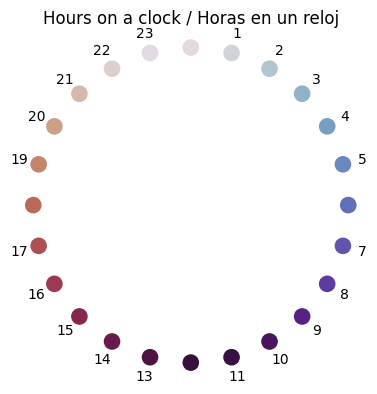

In [4]:
h = np.arange(24)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24), c=h, cmap="twilight", s=120)
for i in h:
    ax.annotate(str(i), (np.sin(2 * np.pi * i / 24) * 1.13, np.cos(2 * np.pi * i / 24) * 1.13), ha="center", va="center")
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Hours on a clock / Horas en un reloj")
plt.show()

## 3️⃣ ⚠️ DATA LEAKAGE demo — "cheating without knowing"
### Demostración de FUGA DE DATOS — "hacer trampa sin darse cuenta"

**EN:** Let's add a clue that *accidentally* uses the future: a moving average **centered** on the candle
(it averages the hour before, the current hour AND the hour after). It looks innocent...

**ES:** Agreguemos una pista que *sin querer* usa el futuro: una media móvil **centrada** en la vela
(promedia la hora anterior, la actual Y la siguiente). Parece inocente...

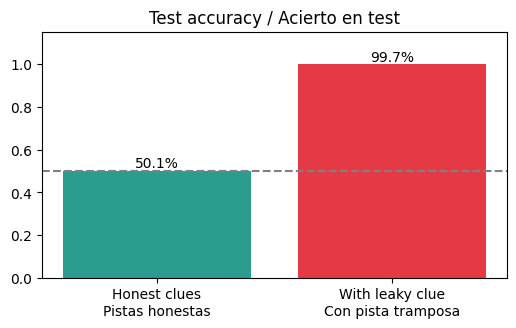

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cut = int(len(X) * 0.8)
honest_cols = [c for c in X.columns if c not in ("time", "target")]

leaky = X.copy()
centered = close.rolling(3, center=True).mean()           # ← silently uses candle t+1 !!
leaky["leaky_clue"] = (centered / close - 1).loc[leaky.index]
leaky = leaky.dropna()  # the last hour has no "future" to peek at

def score(data, cols):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(data[cols].iloc[:cut], data["target"].iloc[:cut])
    return accuracy_score(data["target"].iloc[cut:], m.predict(data[cols].iloc[cut:]))

acc_honest = score(X, honest_cols)
acc_leaky = score(leaky, honest_cols + ["leaky_clue"])

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(["Honest clues\nPistas honestas", "With leaky clue\nCon pista tramposa"],
              [acc_honest, acc_leaky], color=["#2a9d8f", "#e63946"])
ax.bar_label(bars, fmt="%.1f%%", labels=[f"{acc_honest:.1%}", f"{acc_leaky:.1%}"])
ax.axhline(0.5, color="grey", ls="--")
ax.set_ylim(0, 1.15)
ax.set_title("Test accuracy / Acierto en test")
plt.show()

**EN:** 🚨 The leaky model looks like a genius on paper... and would **lose money in real life**, because in
real time the future candles don't exist yet. **Rule:** if results look too good to be true, they are.

**ES:** 🚨 El modelo con fuga parece un genio en el papel... y **perdería dinero en la vida real**, porque en
tiempo real las velas futuras todavía no existen. **Regla:** si los resultados parecen demasiado buenos, lo son.

🛡️ In production we protect against this with an **automatic test** (`test_no_leakage_features_ignore_the_future`):
it changes future prices and checks that today's clues don't change.

---
## 🔁 From notebook to production / Del notebook a producción

| Notebook | Production (`src/features/build.py`) |
|---|---|
| Cells computing clues one by one | One function: `make_features(df, params, with_target=True)` |
| Windows `[10, 50, 200]` typed by hand | `params.yaml → features.sma_windows` |
| Leakage checked by eye | `tests/test_features.py` checks it on **every commit** (CI) |
| Only for training | `with_target=False` → **the API uses the exact same function** (no training/serving skew) |